In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from scipy.linalg import solve_continuous_lyapunov

# Verify TPU/GPU connection
print("Available devices:", jax.devices())

# ==========================================
# 1. Parameter Definition & MDP Setup
# ==========================================
d = 10                   # Number of states in the circular graph
num_actions = 2          # Action 0: Right, Action 1: Left
dim = d * num_actions    # Flattened Q-table dimension

# MDP Parameters
gamma = 0.6
mu_0 = 1.0               # Expected reward going Right
mu_1 = 0.0               # Expected reward going Left
sigma_val = 2.0          # Reward noise variance

# Optimal Q-values (Theoretical Fixed Point)
q_star_0 = mu_0 / (1.0 - gamma)
q_star_1 = mu_1 + gamma * q_star_0
Q_star_np = np.zeros((d, num_actions))
Q_star_np[:, 0] = q_star_0
Q_star_np[:, 1] = q_star_1
Q_star = jnp.array(Q_star_np)

# SA Parameters
c = 1.0
beta_arr = jnp.array([0.4, 0.8])
K = 1e3
num_iters = 50000
num_paths = 200000
eval_interval = 50

chk_k = np.array([200, 500, 1000, 5000, 10000, 30000, 50000])
chk_indices = (chk_k // eval_interval) - 1

# --- Construct the Jacobian of the Bellman Operator J ---
J_np = np.zeros((dim, dim))
for s in range(d):
    for a in range(num_actions):
        idx_from = s * num_actions + a
        s_next = (s + 1) % d if a == 0 else (s - 1) % d
        idx_to = s_next * num_actions + 0
        J_np[idx_from, idx_to] = gamma

# Drift matrix A = J - I
A_np = J_np - np.eye(dim)

# Projection vector
v_proj = np.zeros(dim)
v_proj[0] = 1

# ==========================================
# 2. Core JAX/TPU Simulation Function
# ==========================================
@jax.jit
def tpu_simulate_q_learning(beta, key):
    k_steps = jnp.arange(1, num_iters + 1)
    alphas = c / ((k_steps + K) ** beta)
    num_intervals = num_iters // eval_interval
    alphas_matrix = alphas.reshape((num_intervals, eval_interval))

    save_idx = jnp.full(num_intervals, -1)
    for i, idx in enumerate(chk_indices):
        save_idx = save_idx.at[idx].set(i)

    key = jax.random.PRNGKey(0)
    # Start slightly away from Q* or exactly at Q* depending on preference
    # (Here starting at Q* to observe pure localized noise injection, but can be set to zeros)
    init_Q = jax.random.normal(key, shape=(num_paths, d, num_actions)) + Q_star

    # Checkpoint arrays for W1 histograms (scaled iterate) and MSE
    init_saved_y = jnp.zeros((len(chk_k), num_paths))
    init_saved_mse = jnp.zeros(len(chk_k))

    s_next_0_shift = -1
    s_next_1_shift = 1

    # --- INNER LOOP: Synchronous Q-Learning Updates ---
    def inner_step(inner_carry, alpha_k):
        Q, rng = inner_carry
        rng, key_u = jax.random.split(rng, 2)

        noise = sigma_val * jax.random.normal(key_u, shape=(num_paths, d, num_actions))

        V = jnp.max(Q, axis=-1)
        V_next_0 = jnp.roll(V, shift=s_next_0_shift, axis=-1)
        V_next_1 = jnp.roll(V, shift=s_next_1_shift, axis=-1)

        target_0 = mu_0 + noise[:, :, 0] + gamma * V_next_0
        target_1 = mu_1 + noise[:, :, 1] + gamma * V_next_1
        Q_target = jnp.stack([target_0, target_1], axis=-1)

        Q_next = Q + alpha_k * (Q_target - Q)
        return (Q_next, rng), None

    # --- OUTER LOOP: Periodic Evaluation & Checkpointing ---
    def outer_step(outer_carry, inputs):
        Q, rng, saved_y, saved_mse = outer_carry
        alphas_chunk, s_idx = inputs

        (Q_final, rng_final), _ = jax.lax.scan(inner_step, (Q, rng), alphas_chunk)
        current_alpha = alphas_chunk[-1]

        scaled_Q = (Q_final - Q_star) / jnp.sqrt(current_alpha)
        projected_y = scaled_Q[:, 0, 0]

        def save_y_fn(saved):
            return jax.lax.dynamic_update_slice_in_dim(saved, projected_y[None, :], s_idx, axis=0)

        def save_mse_fn(saved):
            # Compute empirical mean squared error across all paths and Q-table elements
            mse = jnp.mean(jnp.sum((Q_final - Q_star)**2, axis=(1, 2)))
            return jax.lax.dynamic_update_slice_in_dim(saved, jnp.array([mse]), s_idx, axis=0)

        def skip_fn(saved):
            return saved

        saved_y_next = jax.lax.cond(s_idx >= 0, save_y_fn, skip_fn, saved_y)
        saved_mse_next = jax.lax.cond(s_idx >= 0, save_mse_fn, skip_fn, saved_mse)

        return (Q_final, rng_final, saved_y_next, saved_mse_next), None

    final_carry, _ = jax.lax.scan(outer_step, (init_Q, key, init_saved_y, init_saved_mse), (alphas_matrix, save_idx))
    return final_carry[2], final_carry[3]

def compute_asymptotic_covariance():
    Sigma_noise = (sigma_val**2) * np.eye(dim)
    Sigma_inf = solve_continuous_lyapunov(A_np, -Sigma_noise)
    variance_q00 = v_proj.T @ Sigma_inf @ v_proj
    return np.sqrt(variance_q00)

# ==========================================
# 4. Execution
# ==========================================
vmap_simulate = jax.vmap(tpu_simulate_q_learning, in_axes=(0, 0))

master_key = jax.random.PRNGKey(42)
keys = jax.random.split(master_key, len(beta_arr))

print(f"Executing Q-Learning on TPU for {num_iters} steps with {num_paths} paths...")
all_saved_ys, all_saved_mses = vmap_simulate(beta_arr, keys)

all_saved_ys = np.array(all_saved_ys)
all_saved_mses = np.array(all_saved_mses)
print("Simulation complete.")

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


Available devices: [TpuDevice(id=0, process_index=0, coords=(0,0,0), core_on_chip=0)]
Executing Q-Learning on TPU for 50000 steps with 200000 paths...
Simulation complete.


100%|██████████| 50000/50000 [00:00<00:00, 86214.63it/s]


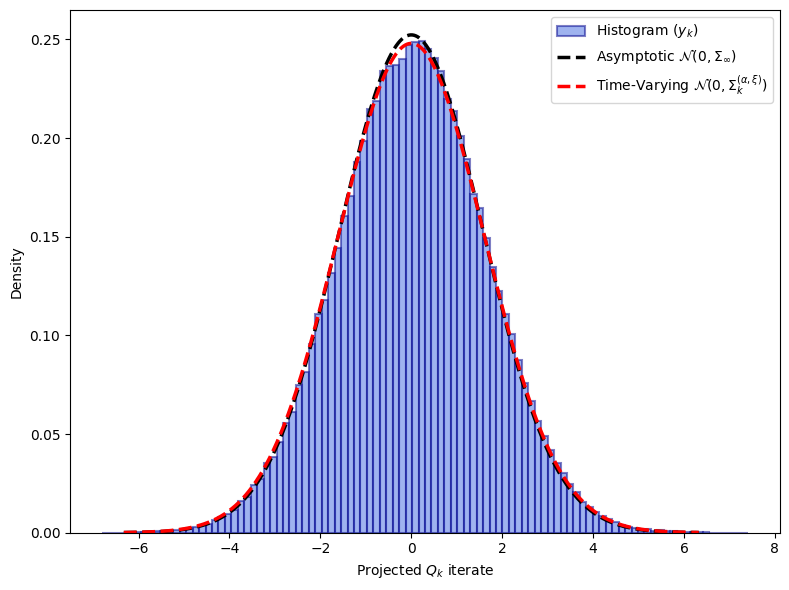

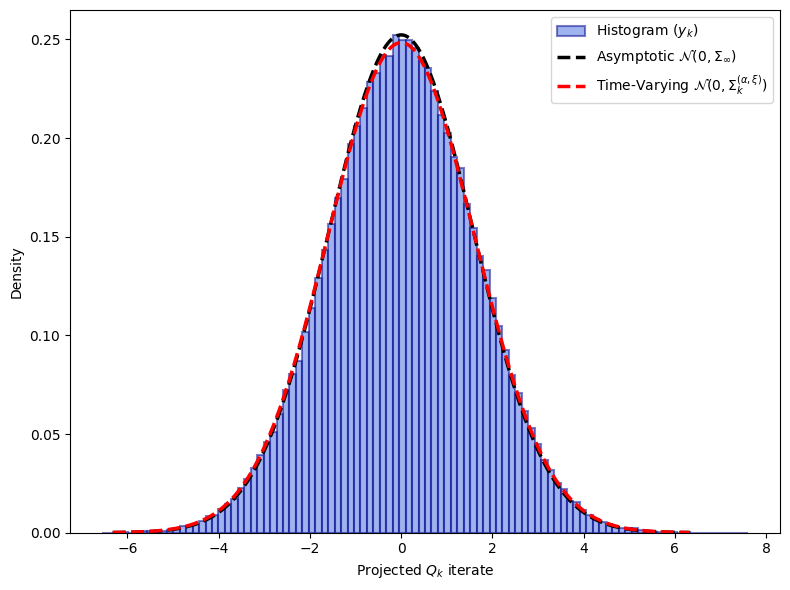

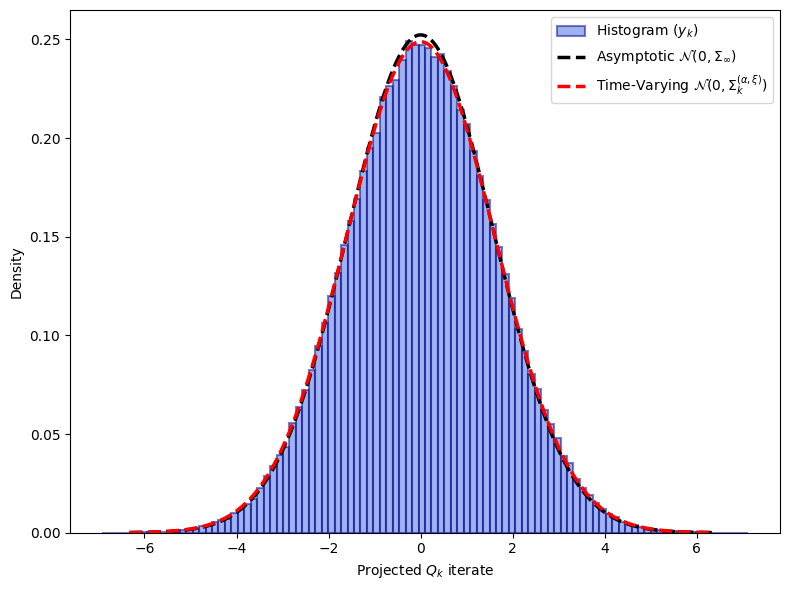

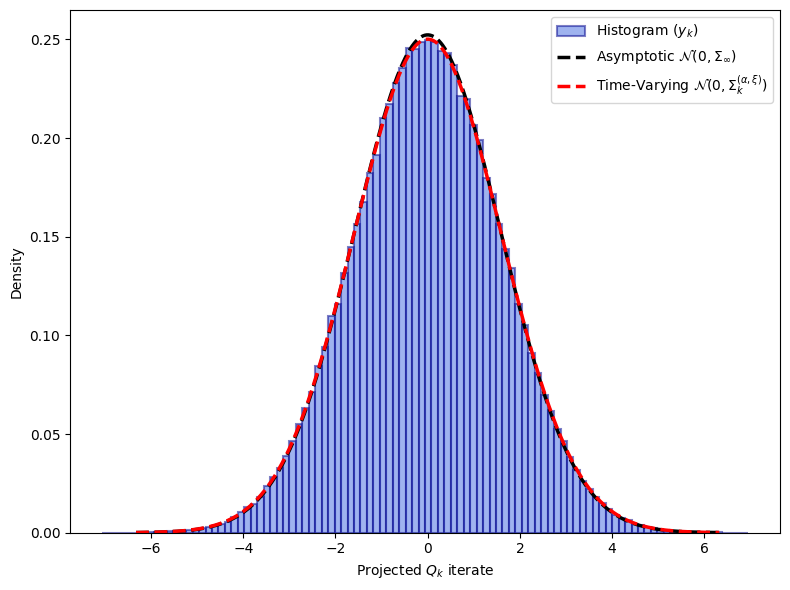

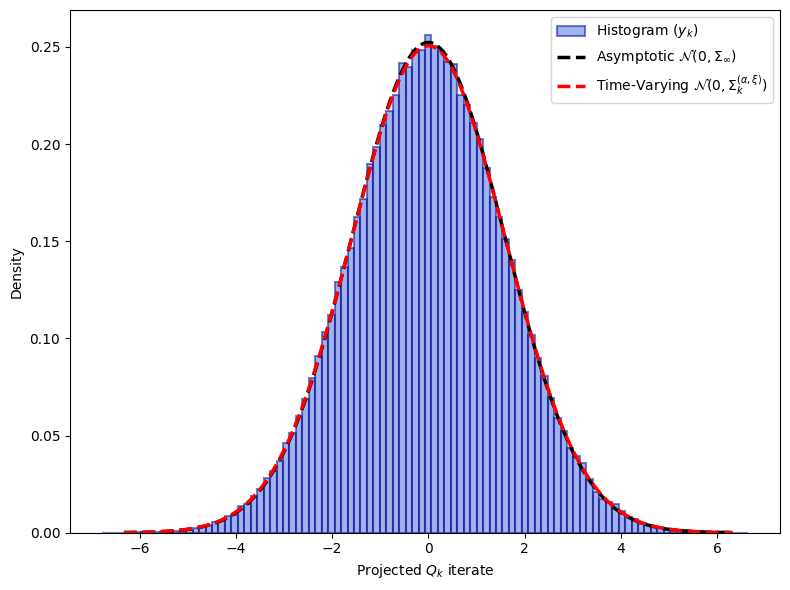

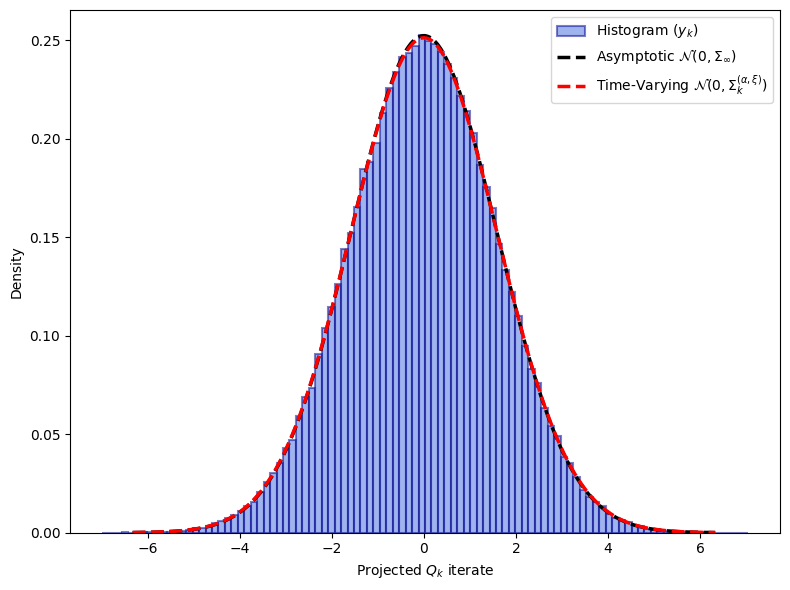

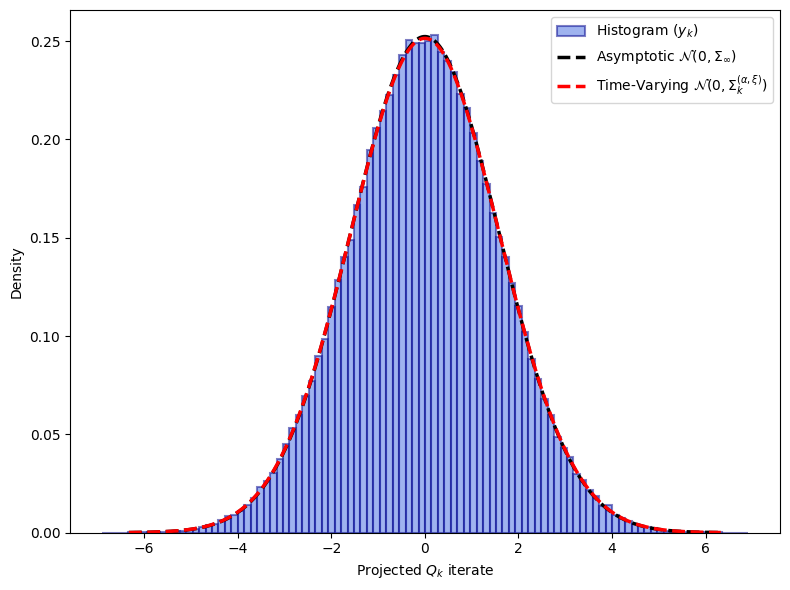

100%|██████████| 50000/50000 [00:00<00:00, 88061.79it/s]


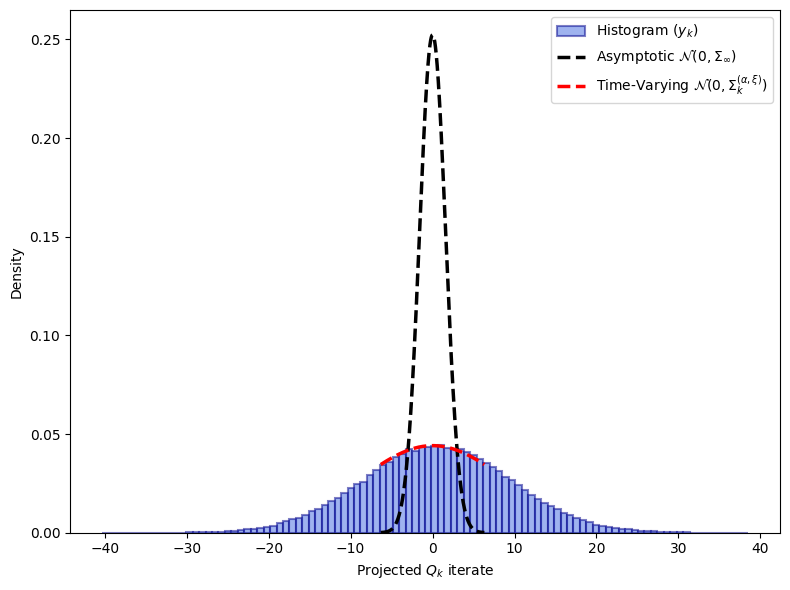

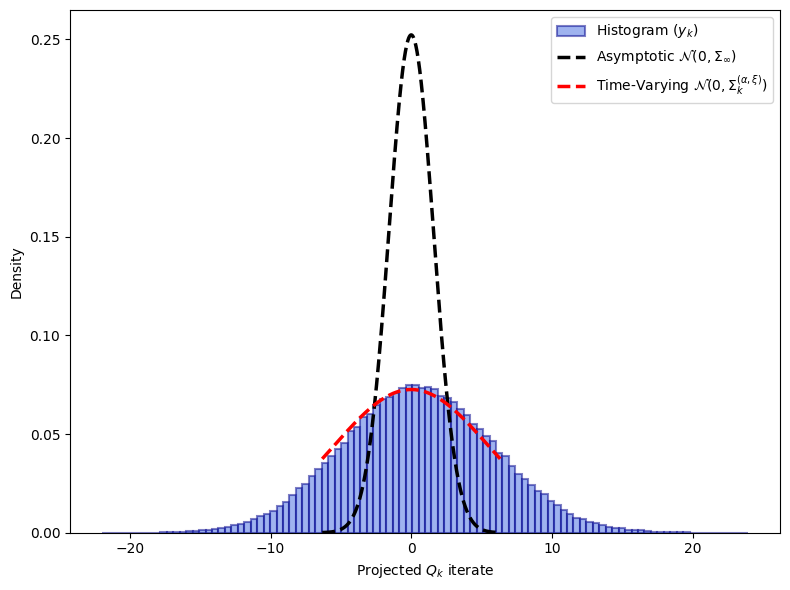

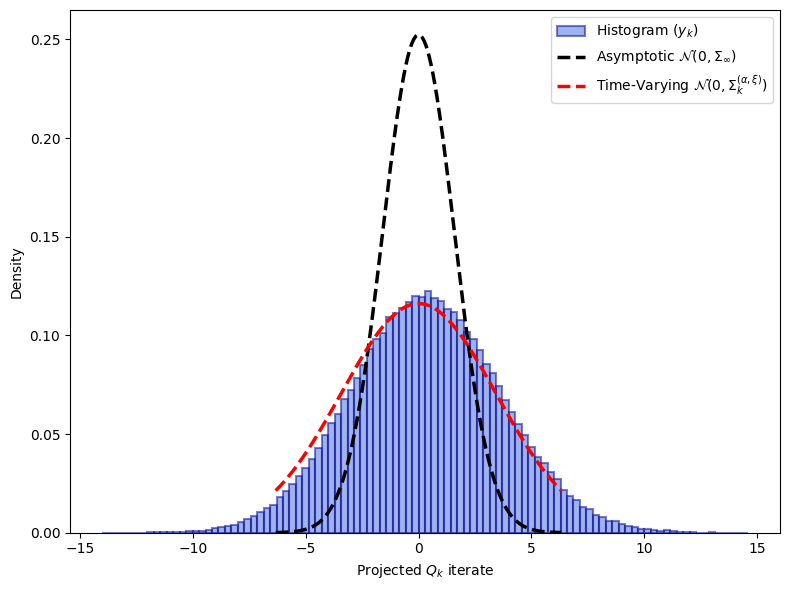

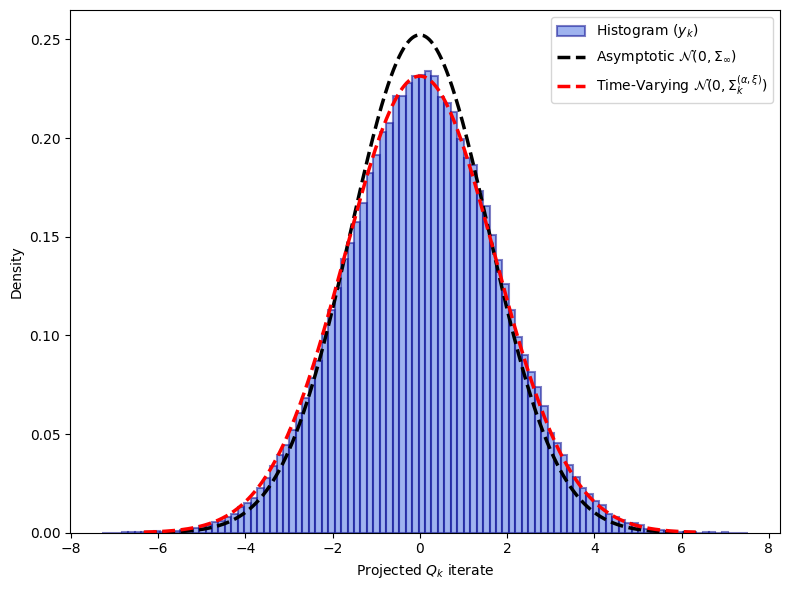

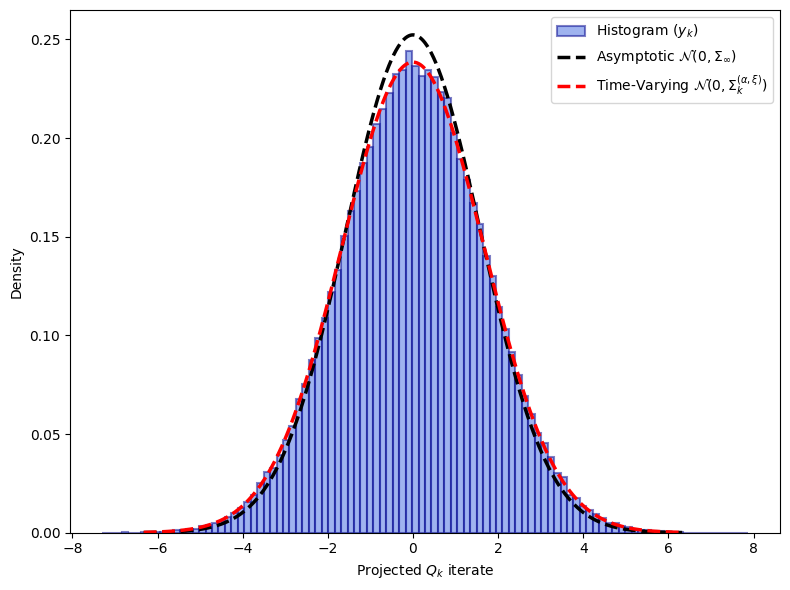

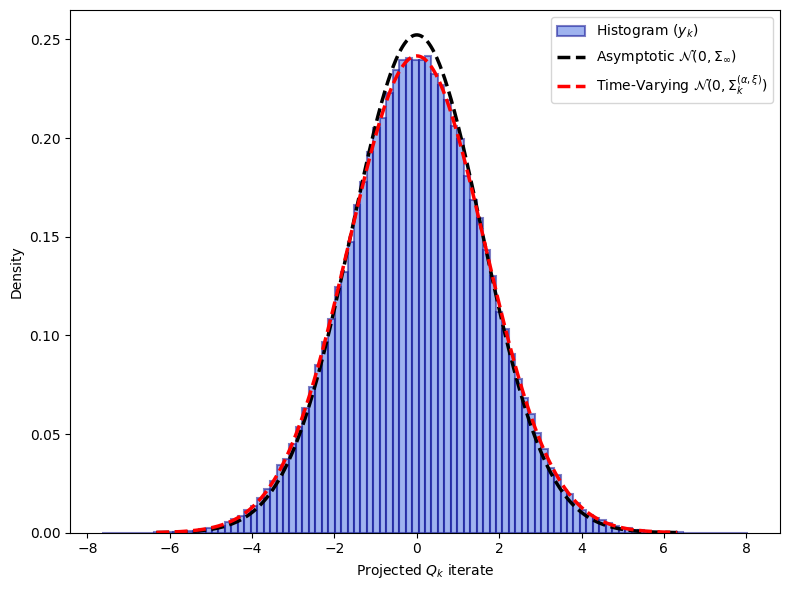

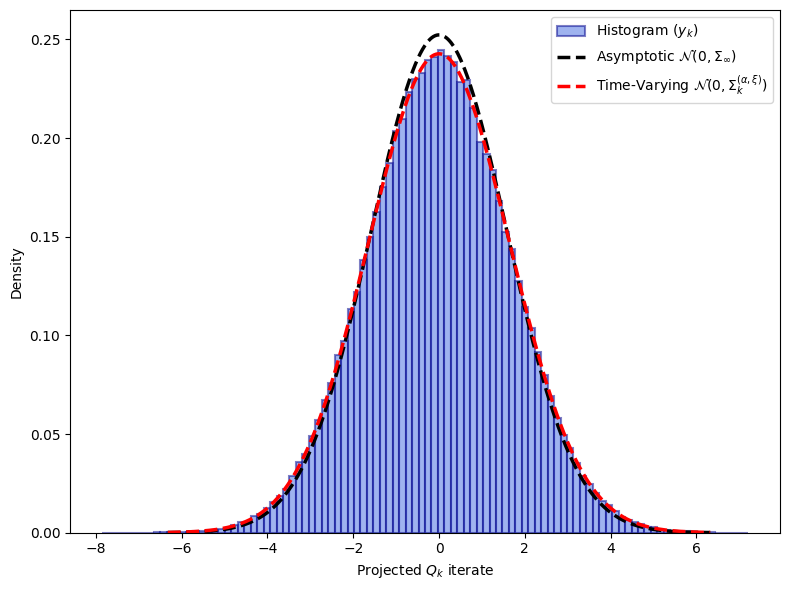

In [2]:
# ==========================================
# 6. Plotting W1 Distances & Histograms
# ==========================================
from tqdm import tqdm
asymptotic_std = compute_asymptotic_covariance()
x_grid = np.linspace(-4 * asymptotic_std, 4 * asymptotic_std, 1000)
pdf_asymp = stats.norm.pdf(x_grid, 0, asymptotic_std)
Sigma_noise = (sigma_val**2) * np.eye(dim)
k_steps = np.arange(1, num_iters + 1)

for idx, beta in enumerate(np.asarray(beta_arr)): ## Perform the calculations in numpy instead of JAX since it does a lot of approximation for speed
    beta = float(beta)
    alphas = c / ((k_steps + K) ** beta)

    sigmas = np.zeros((num_iters + 1, dim, dim))
    sigmas[0] = np.eye(dim) / alphas[0]
    I = np.eye(dim)

    for k in tqdm(range(num_iters)):
        alpha_k = alphas[k]
        shrinkage = I + alpha_k * A_np + (beta / (2 * (k + K))) * I
        sigmas[k+1] = shrinkage @ sigmas[k] @ shrinkage.T + alpha_k * Sigma_noise

    for i, k in enumerate(chk_k):
        fig, ax = plt.subplots(figsize=(8, 6))

        empirical_data = all_saved_ys[idx, i, ::1]
        ax.hist(empirical_data, bins=100, density=True, alpha=0.5, color='royalblue',
                edgecolor='darkblue', linewidth=1.5, label=f'Histogram $(y_k)$')

        ax.plot(x_grid, pdf_asymp, 'k--', linewidth=2.5,
                label=r'Asymptotic $\mathcal{N}(0, \Sigma_{\infty})$')

        current_std = np.sqrt(v_proj.T @ sigmas[k] @ v_proj)
        pdf_time = stats.norm.pdf(x_grid, 0, current_std)
        ax.plot(x_grid, pdf_time, 'r--', linewidth=2.5,
                label=r'Time-Varying $\mathcal{N}(0, \Sigma_k^{(\alpha, \xi)})$')

        # ax.set_title(f'Q-Learning Distribution Evolution ($\\beta = {beta:.2f}$) | Scaled Iterate at $k = {k}$', fontsize=14)
        ax.set_xlabel('Projected $Q_k$ iterate')
        ax.set_ylabel('Density')
        ax.legend(loc='upper right')

        plt.tight_layout()
        plt.show()